In [1]:
import torch
import os 
import torchvision
import torch.optim 
import torch.nn as nn
import torch.utils as vutils 
from torch.utils.data import dataloader , dataset
from torchvision.transforms import v2
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm 
from timeit import default_timer as timer 
print(torch.__version__) 

2.11.0+cpu


In [2]:
train_transform = v2.Compose([
    v2.Resize((128, 128)),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.485, 0.456, 0.406),(0.229, 0.224 , 0.255))
])

test_transform = v2.Compose([
    v2.Resize((64, 64)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.485, 0.456, 0.406),(0.229, 0.224 , 0.255))
])

In [6]:
train_dataset = torchvision.datasets.ImageFolder(root='/kaggle/input/datasets/ayush1220/cifar10/cifar10/train', transform=train_transform)
test_dataset = torchvision.datasets.ImageFolder(root ='/kaggle/input/datasets/ayush1220/cifar10/cifar10/test', transform=test_transform)
print(f"Lenght of the train dataset:{len(train_dataset)}")
print(f"Lenght of the test dataset:{len(test_dataset)}")

Lenght of the train dataset:50000
Lenght of the test dataset:10000


In [7]:
trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, drop_last=True)
testloader  = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, drop_last=True)

print(f"Lenght of the train dataloader:{len(trainloader)}")
print(f"Lenght of the test dataloader:{len(testloader)}")

Lenght of the train dataloader:1562
Lenght of the test dataloader:312


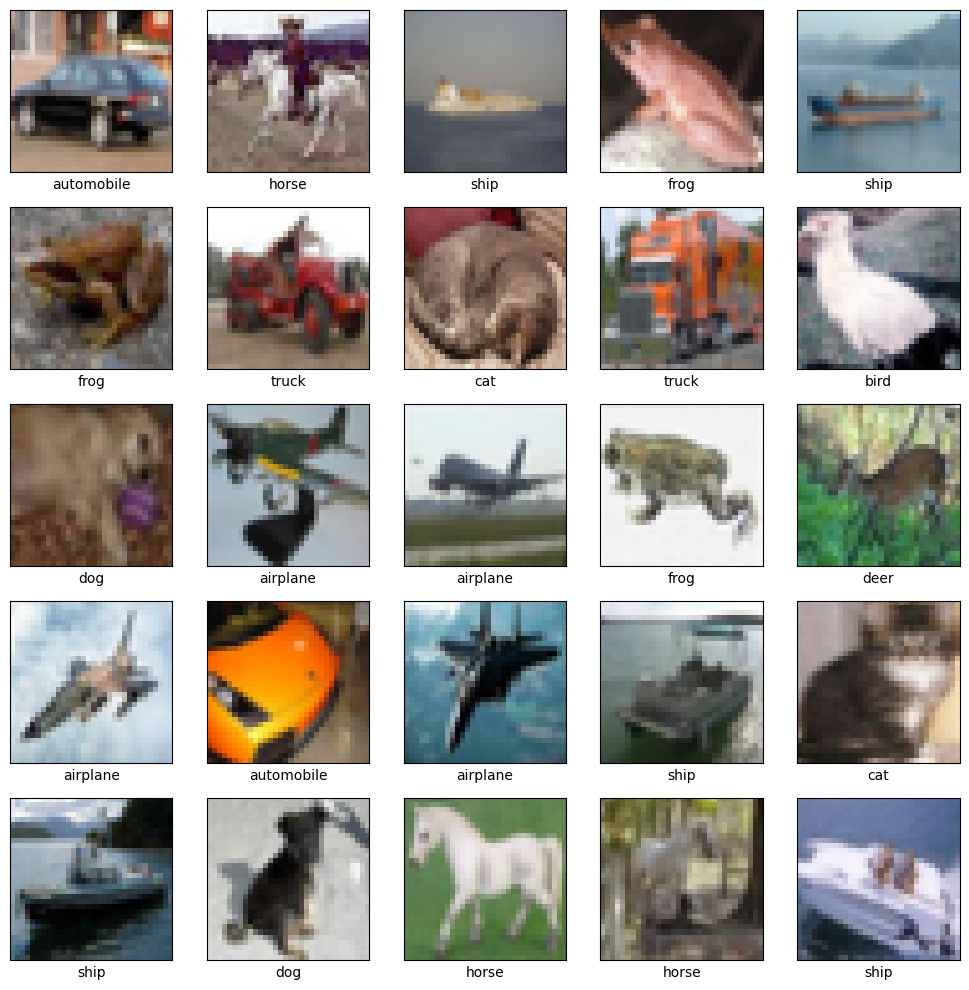

In [8]:
images = torchvision.datasets.ImageFolder(root='/kaggle/input/datasets/ayush1220/cifar10/cifar10/train')
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    
    
    # Pick a random index
    idx = np.random.randint(0, len(images))
    
    # Get the image object (PIL image) and its label integer
    img, label = images[idx]
    
    plt.imshow(img)
    plt.xlabel(classes[label])

plt.tight_layout()
plt.show()

In [ ]:
#Setting up hyperparameters
patch_size= 4
img_size=32
embed_dim = 256
in_channels = 3
drop_rate = 0.1

In [ ]:
#Patch embedding 
class Patch_Embedding(torch.nn.Module):
  def __init__(self, img_size, in_channels, patch_size, embed_dim) -> None:
     super().__init__()
     self.patch_size = patch_size
     self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)
     self.num_patchs = (img_size // patch_size)**2
     self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
     self.pos_embed = nn.Parameter(torch.randn(1, 1 + self.num_patchs, embed_dim))

  def forward(self, x:torch.Tensor):
    B = x.size(0)
    x = self.proj(x)
    x = x.Flatten(2).transpose(1,2)
    cls_token = self.cls_token.expand(B, -1, -1)
    x = torch.cat([cls_token, x], dim=1)
    x = x + self.pos_embed
    return x

In [ ]:
class MLP(torch.nn.Module):
  def __init__(self, in_features, hidden_features, drop_rate) -> None:
     super().__init__()
     self.fc1 = nn.Linear(in_features, hidden_features)
     self.fc2 = nn.Linear(hidden_features, hidden_features)
     self.dropout = nn.Dropout(drop_rate)
  def forward(self, x:torch.Tensor):
    x = self.dropout(F.gelu(self.fc1(x)))
    x = self.dropout(self.fc2(x))
    return x

In [ ]:
class TransformerEncoderLayer(nn.Module):
  def __init__(self, embed_dim, num_heads, mlp_dim, drop_rate) -> None:
     super().__init__()
     self.norm1 = nn.LayerNorm(embed_dim)
     self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=drop_rate, batch_first=True)
     self.norm2 = nn.LayerNorm(embed_dim)
     self.mlp = MLP(embed_dim, mlp_dim, drop_rate)
  def forward(self, x):
    x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
    x = x + self.mlp(self.norm2(x))
    return x 